# Monte Carlo - Inversión de CDF desde archivo de datos reales

## 📁 Paso 1: Leer archivo y graficar la distribución
```python
import numpy as np
import matplotlib.pyplot as plt

# Cargar archivo con tres columnas (bin, intensidad, incertidumbre)
data = np.loadtxt("661kev-Cs137.txt")
x = data[:, 0]  # valores de bin
f = data[:, 1]  # intensidad

# Graficar la distribución original
plt.plot(x, f, label="Distribución original")
plt.title("Distribución espectral original (sin normalizar)")
plt.xlabel("Canal o energía")
plt.ylabel("Intensidad")
plt.grid()
plt.legend()
plt.show()
```

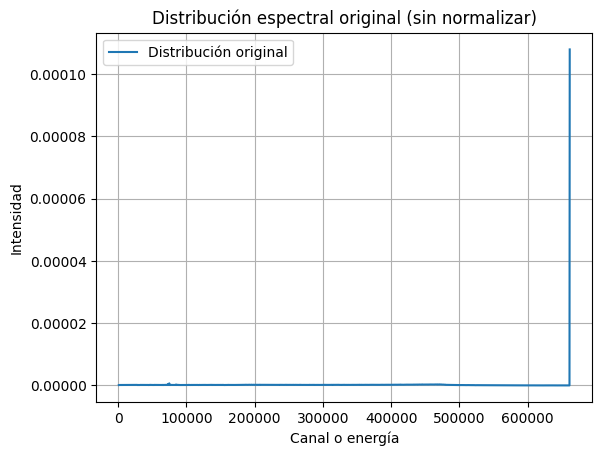

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Cargar archivo con tres columnas (bin, intensidad, incertidumbre)
data = np.loadtxt("661kev-Cs137.txt")
x = data[:, 0]  # valores de bin
f = data[:, 1]  # intensidad

# Graficar la distribución original
# plt.yscale('log')
plt.plot(x, f, label="Distribución original")
plt.title("Distribución espectral original (sin normalizar)")
plt.xlabel("Canal o energía")
plt.ylabel("Intensidad")
plt.grid()
plt.legend()
plt.show()

## ➕ Paso 2: Construir la CDF (integración acumulada)
```python
# Calcular delta x para integración (se asume espaciado uniforme)
dx = np.diff(x).mean()
cdf = np.cumsum(f) * dx
cdf /= cdf[-1]  # normalizar

plt.yscale('log')
plt.plot(x, cdf, label="CDF acumulada")
plt.title("Función de distribución acumulada (CDF)")
plt.xlabel("Canal o energía")
plt.ylabel("Probabilidad acumulada")
plt.grid()
plt.legend()
plt.show()
```

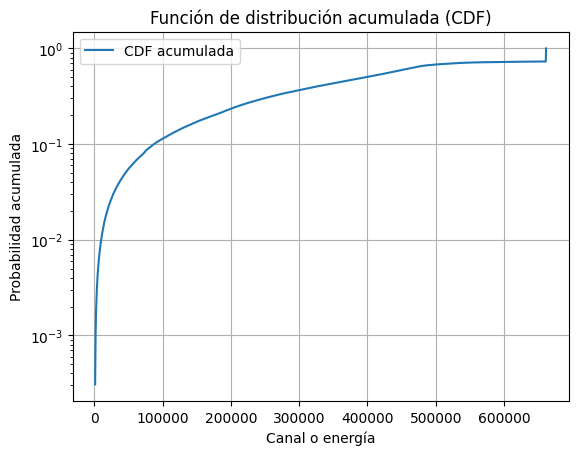

In [2]:
# Calcular delta x para integración (se asume espaciado uniforme)
dx = np.diff(x).mean()
cdf = np.cumsum(f) * dx
cdf /= cdf[-1]  # normalizar

plt.yscale('log')
plt.plot(x, cdf, label="CDF acumulada")
plt.title("Función de distribución acumulada (CDF)")
plt.xlabel("Canal o energía")
plt.ylabel("Probabilidad acumulada")
plt.grid()
plt.legend()
plt.show()

## 🔄 Paso 3: Invertir la CDF
```python
from scipy.interpolate import interp1d

# Interpolar inversa de la CDF
to_random = interp1d(cdf, x)

# Graficar inversa (visual)
y_vals = np.linspace(0, 1, 500)
x_invertida = to_random(y_vals)

plt.plot(y_vals, x_invertida)
plt.title("Inversa de la CDF")
plt.xlabel("Probabilidad acumulada")
plt.ylabel("Canal o energía")
plt.grid()
plt.show()
```

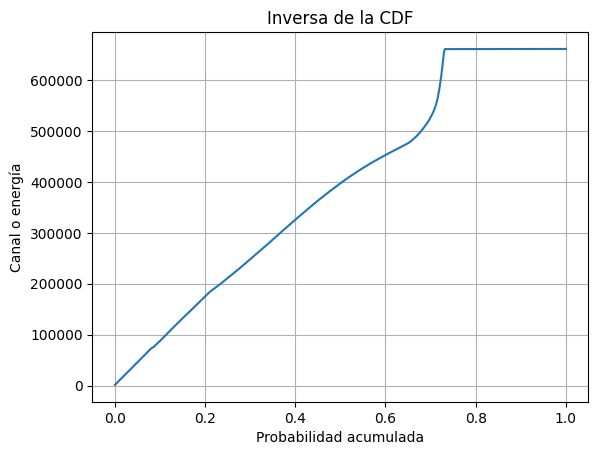

In [5]:
from scipy.interpolate import interp1d

# Interpolar inversa de la CDF
to_random = interp1d(cdf, x)

# Graficar inversa (visual)
y_vals = np.linspace(cdf[0], cdf[-1], 500)
x_invertida = to_random(y_vals)

#y_vals = np.linspace(0, 1, 500)
#x_invertida = to_random(y_vals)
#plt.xscale('log')
plt.plot(y_vals, x_invertida)
plt.title("Inversa de la CDF")
plt.xlabel("Probabilidad acumulada")
plt.ylabel("Canal o energía")
plt.grid()
plt.show()

## 🚀 Paso 4: Generar muestras y comparar
```python
samples = to_random(np.random.uniform(0, 1, 100000))

plt.hist(samples, bins=200, density=True, alpha=0.6, label="Simuladas")
plt.plot(x, f / np.trapz(f, x), 'r--', label="Original normalizada")
plt.title("Distribución simulada vs. original")
plt.xlabel("Canal o energía")
plt.ylabel("Densidad")
plt.legend()
plt.grid()
plt.show()
```

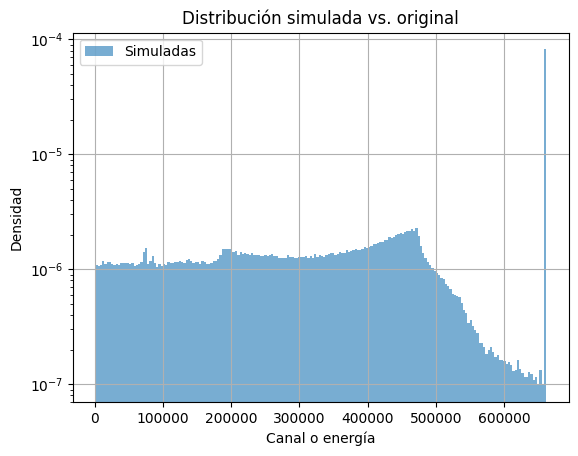

In [11]:
# samples = to_random(np.random.uniform(0, 1, 100000))

u = np.random.uniform(cdf[0], cdf[-1], 1000000)
samples = to_random(u)

plt.yscale('log')
plt.hist(samples, bins=200, density=True, alpha=0.6, label="Simuladas")
#plt.plot(x, f / np.trapezoid(f, x), 'r--', label="Original normalizada")
plt.title("Distribución simulada vs. original")
plt.xlabel("Canal o energía")
plt.ylabel("Densidad")
plt.legend()
plt.grid()
plt.show()

## ✅ Conclusión
"""
Este notebook muestra cómo generar muestras aleatorias según una distribución real medida,
leyendo desde un archivo y aplicando el método de inversión de la CDF.
"""